<a href="https://colab.research.google.com/github/hawinmislon/HCL-PROGRAMS/blob/main/Assignment1_ML_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print("Dataset size:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nIncome categories:")
print(df["income"].value_counts())

Dataset size:
(32561, 15)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB

Missing values:
age                  0
workcl

In [4]:
# Remove duplicate records
df = df.drop_duplicates()

# Remove records with a missing target
df = df.dropna(subset=["income"])

print("Data cleaning completed!")
print("Remaining records:", len(df))

print("\nMissing values in each column:")
print(df.isnull().sum())

Data cleaning completed!
Remaining records: 32537

Missing values in each column:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     582
income               0
dtype: int64


In [5]:
# Separate input features and target
X = df.drop("income", axis=1)

y = (
    df["income"]
    .str.strip()
    .str.replace(".", "", regex=False)
)

# Identify numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


In [6]:
# Preprocess numerical columns
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

print("Preprocessing setup completed!")

Preprocessing setup completed!


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 26029
Testing records: 6508


In [8]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [9]:
# Predict income categories
y_pred = model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label=">50K"
)

recall = recall_score(
    y_test, y_pred, pos_label=">50K"
)

f1 = f1_score(
    y_test, y_pred, pos_label=">50K"
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred))

MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.8605
Precision: 0.7444
Recall   : 0.6409
F1-score : 0.6888

Detailed Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.64      0.69      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.79      0.80      6508
weighted avg       0.86      0.86      0.86      6508



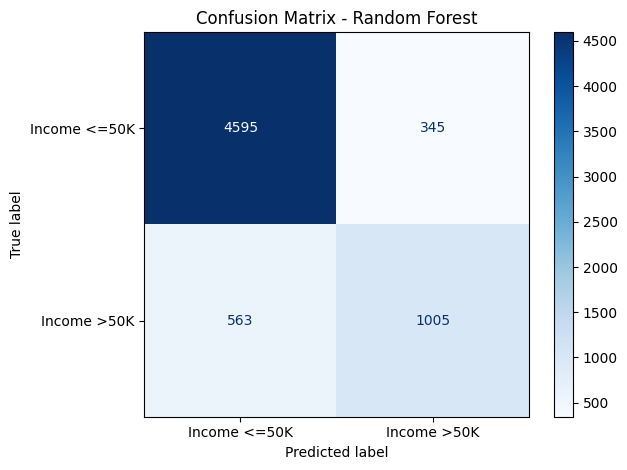

In [10]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["<=50K", ">50K"],
    display_labels=["Income <=50K", "Income >50K"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

Top 10 important features:


,Feature,Importance
1,numerical__fnlwgt,0.163672
0,numerical__age,0.149866
3,numerical__capital_gain,0.094402
5,numerical__hours_per_week,0.082530
2,numerical__education_num,0.063147
32,categorical__marital_status_Married-civ-spouse,0.058291
51,categorical__relationship_Husband,0.052595
4,numerical__capital_loss,0.031052
34,categorical__marital_status_Never-married,0.024870
40,categorical__occupation_Exec-managerial,0.016742


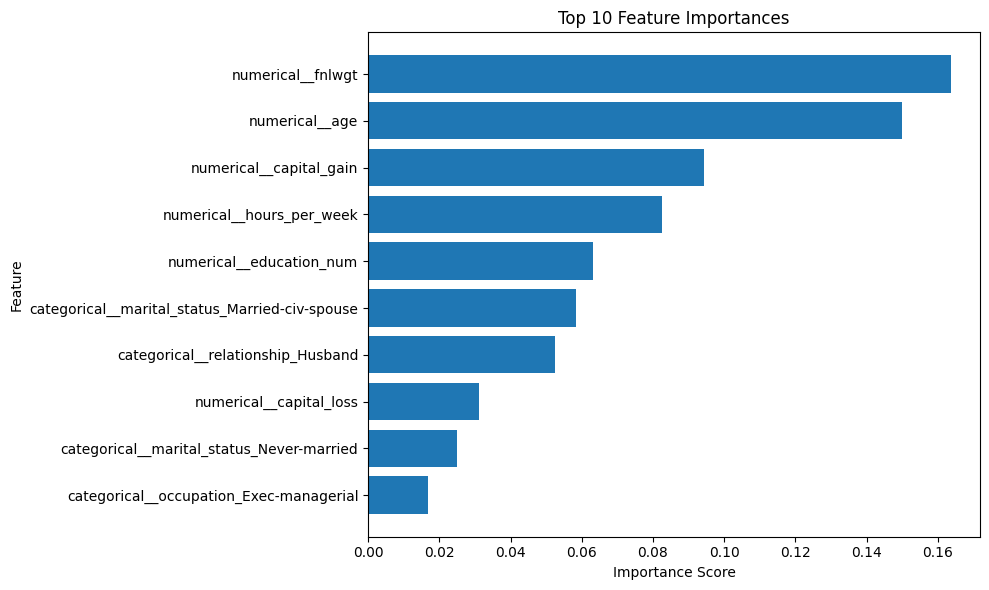

In [11]:
# Get feature names after preprocessing
feature_names = (
    model.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Get feature importance scores
importances = (
    model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 important features:")
display(importance_df.head(10))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

An end-to-end Machine Learning pipeline was developed using the UCI Adult Income dataset. The dataset was explored and cleaned, and missing values were handled using suitable preprocessing techniques. Numerical features were scaled, while categorical features were encoded using One-Hot Encoding. The dataset was divided into training and testing sets, and a Random Forest Classifier was trained to predict income categories. Model performance was evaluated using accuracy, precision, recall, F1-score, and a confusion matrix. Feature importance was also analyzed to identify the features most influential in the model's predictions. This assignment demonstrates the complete Machine Learning workflow, from data preparation to model evaluation.